# How deep are the mitoses? `mo_pad61`'s whole candidate pool, 49 ROIs x 6 clicks, post-D11

**Why.** In the pad-arms run, the top 30 at `tm_score` holds about 13 mitoses on the median ROI, but about 2 on the five
"stuck" ROIs (`211`, `242`, `462`, `524`, `546`). Re-ranking the top 30 by shape can't lift those five: there is almost
nothing in it to promote. A shape score could only help if their mitoses sit further down the list. This notebook
measures how far down.

**What is run.** One arm, `mo_pad61`, re-searched on all 294 recorded clicks. It is the pad-arms run's search, copied,
with one change: **no peak cap**. The recorded run kept the best 100 peaks before NMS (`MAX_PEAKS = 100`, which bound on
every search). Here every peak above the deep floor (median - 1.5 MAD of the response map) is kept, NMS runs on all of
them, and the pool is read at post-NMS ranks N = 10, 30, 100, 300 and 1000, and in full.

**Why the recorded run is a prefix of this one.** `extract_peaks` orders peaks with a global tie-break, greedy NMS runs
in descending score order, and `greedy_match` claims annotations in rank order. So a lower-ranked peak can never change
a higher one, and the recorded 100-peak pool must be exactly this pool's first rows.

**Gates, on every click, halting on the first failure.**
- The `mo_pad61` template is rebuilt from the TIFF and its SHA-1 must equal the recorded `tpl_sha1`.
- NMS on the first 100 peaks alone must give the recorded `n_detections`, and those survivors must be the deep pool's
  first rows.
- The first 30 at `tm_score` must equal the recorded top 30 (`rank`, `cx`, `cy`, float32 `score`, `bucket`,
  `matched_ann_id`), and `tp_at_10/20/30` must equal the recorded values.
- Re-ranking that 100-peak prefix by `od` must reproduce the recorded `chromatin_od` top 30 and its `tp_at_10/20/30`.

**What is reported, and why each number is paired.** A pool with no cap eventually covers most of the ROI, so "the
mitosis is somewhere in the top 1000" is close to guaranteed and says little by itself. Each depth N therefore carries:
- **mitoses in the top N** and **recall at N**, the share of that ROI's mitoses (the clicked one excluded) that the top
  N finds. Recall is needed because the five ROIs have 15-28 mitoses against more elsewhere;
- **chance recall at N**: the share of the ROI lying within the 7.5 um match radius of a top-N detection
  (`ev.coverage_fraction`). Detections placed at random would find about this share of mitoses;
- **mitoses per detection** in the top N: what a random re-ordering of that pool would put in a top 10;
- **the ceiling**: `min(10, mitoses in the top N) / 10`, the precision@10 a perfect re-ranker of that pool could reach.
  It is optimistic: a real shape score has to find those mitoses at the pool's own mitoses-per-detection rate.

Plus one row per (click, annotated mitosis): the `tm_score` rank at which the full list first matches it.

**Scope.** Descriptive only: no tests. The five ROIs were picked for their poor top 10, so comparing them with the
other 44 is a description, not a finding.

**Outputs.** `results/deep_pool_mo_pad61_49roi_6seed_postD11_{per_run,gt_rank,top1000}.csv`. `top1000` keeps each
search's first 1000 detections with `od`, for later re-ranking work; the full pool is not saved.

In [1]:
import gc
import hashlib
import os
import sys
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

sys.path.insert(0, '..')
from midog_utils import channels as ch
from midog_utils import chromatin as cm
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import invariants as inv
from midog_utils import production as prod
from midog_utils import template_match as tm
from midog_utils.nms import nms_by_distance

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)

NB_T0 = time.time()

# the configuration the recorded pad-arms run used, asserted against midog_utils.production
REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
assert all(getattr(prod, k) == v for k, v in REFERENCE_CONFIG.items()), 'midog_utils.production no longer matches the configuration the recorded run used'
assert ev.MIDOG_RADIUS_UM == 7.5, 'D7: NMS radius = match radius = 7.5 um'
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73), 'the template and patch sizes this notebook hard-codes'
assert hasattr(tm, 'blank_seed_square') and not hasattr(prod, 'SELF_HIT_RADIUS'), 'this is not post-D11 code'

ARM = 'mo_pad61'
RECORDED_MAX_PEAKS = prod.MAX_PEAKS    # 100: the recorded cap, re-applied only to rebuild the recorded pool as a prefix
UNCAPPED = 10 ** 9                     # extract_peaks' max_peaks here: no cap, so only the deep floor limits the pool
DEPTHS = (10, 30, 100, 300, 1000)      # post-NMS ranks at which the pool is read
SAVE_TOP = 1000                        # detections per search written to the top1000 CSV, with od
STUCK = ('211.tiff', '242.tiff', '462.tiff', '524.tiff', '546.tiff')
AXIS_KEY = {'chromatin_od': 'od', 'tm_score': 'score'}
assert AXIS_KEY == prod.AXES

# the pad-arms run's template and search constants, verbatim
BASE_SIZE = tm.BASE_SIZE
BLANK_SIZE = 51                        # the blanked square: 51 x 51, centred on the click, as recorded
OD_PAD = 25                            # the od channel's replicate pad
MAX_SIDE = 2 * (tm.PATCH_SIZE // 2) + 1
EDGE_READ_PAD = tm.PATCH_SIZE // 2
RING_PX = 5
ARMS = ('mo_box', 'mo_pad51', 'mo_pad61', 'mo_ring5')   # build_mo_templates builds all four, as recorded; only mo_pad61 is searched
PAD_ARMS = ('mo_pad51', 'mo_pad61')

SMOKE_ROIS = [s for s in os.environ.get('DEEPPOOL_SMOKE_ROIS', '').split(',') if s] or None   # None = all 49 ROIs
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
MO_SRC = '../results/precision_at_k_49roi_6seed_mopad_postD11'
FG_SRC = '../results/precision_at_k_49roi_6seed_fillgeom_postD11'
DB_PATH = '../databases/MIDOG++.json'
SUBSET_DIRS = {'original_14': '../images/extra_valid', 'testing_35': '../images/extra_valid/testing_set'}
OUT_STEM = f'../results/deep_pool_mo_pad61_49roi_6seed_postD11{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('per_run', 'gt_rank', 'top1000')}
FIG_PATH = f'deep_pool_recall_precision{SUFFIX}.png'
print(f'arm {ARM}; no peak cap; depths {DEPTHS}; smoke ROIs = {SMOKE_ROIS}')
print('outputs:', *OUT.values(), FIG_PATH, sep='\n  ')

arm mo_pad61; no peak cap; depths (10, 30, 100, 300, 1000); smoke ROIs = None
outputs:
  ../results/deep_pool_mo_pad61_49roi_6seed_postD11_per_run.csv
  ../results/deep_pool_mo_pad61_49roi_6seed_postD11_gt_rank.csv
  ../results/deep_pool_mo_pad61_49roi_6seed_postD11_top1000.csv
  deep_pool_recall_precision.png


In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


for p in (f'{FG_SRC}_clicks.csv', f'{MO_SRC}_templates.csv', f'{MO_SRC}_per_run.csv', f'{MO_SRC}_top30.csv', DB_PATH):
    print(f'  {sha256_12(p)}  {p}')

CLICKS = pd.read_csv(f'{FG_SRC}_clicks.csv', float_precision='round_trip')
TPL = pd.read_csv(f'{MO_SRC}_templates.csv', float_precision='round_trip').query('condition == @ARM')
REC_RUN = pd.read_csv(f'{MO_SRC}_per_run.csv', float_precision='round_trip').query('condition == @ARM')
REC_TOP = pd.read_csv(f'{MO_SRC}_top30.csv', float_precision='round_trip').query('condition == @ARM')
assert (len(CLICKS), len(TPL), len(REC_RUN), len(REC_TOP)) == (294, 294, 588, 588 * 30), 'a recorded input does not have its expected row count'
assert TPL['accepted'].all() and (TPL['S'] == 61).all(), f'{ARM}: a refused click, or a template side other than 61'
assert (REC_RUN['n_peaks'] == RECORDED_MAX_PEAKS).all(), 'the recorded cap did not bind on every search'

TPL_IX = TPL.set_index(['file_name', 'seed_index']).sort_index()
REC_RUN_IX = REC_RUN.set_index(['file_name', 'seed_index', 'rank_key']).sort_index()
REC_TOP_IX = {key: g.sort_values('rank').reset_index(drop=True) for key, g in REC_TOP.groupby(['file_name', 'seed_index', 'rank_key'])}
chk = TPL.merge(CLICKS[['file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy']], on=['file_name', 'seed_index'], suffixes=('', '_clk'), validate='one_to_one')
assert (chk['seed_ann_id'] == chk['seed_ann_id_clk']).all() and (chk['click_cx'] == chk['click_cx_clk']).all() and (chk['click_cy'] == chk['click_cy_clk']).all(), 'the templates CSV is not on the clicks CSV clicks'

ROI_ORDER_ALL = list(pd.unique(REC_RUN['file_name']))
assert len(ROI_ORDER_ALL) == 49 and set(STUCK) <= set(ROI_ORDER_ALL)
ROI_ORDER = ROI_ORDER_ALL if SMOKE_ROIS is None else [f for f in ROI_ORDER_ALL if f in SMOKE_ROIS]
assert SMOKE_ROIS is None or sorted(ROI_ORDER) == sorted(SMOKE_ROIS), f'smoke ROIs not found: {SMOKE_ROIS}'
images, annotations = ds.load_annotations(DB_PATH)
print(f'\n{len(ROI_ORDER)} ROIs x 6 clicks = {6 * len(ROI_ORDER)} searches of {ARM}')

  0d0c2964b8f9  ../results/precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv
  3a14a36932b6  ../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  18c42ce0525c  ../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  d49bf37897ab  ../results/precision_at_k_49roi_6seed_mopad_postD11_top30.csv
  8c87ab4276eb  ../databases/MIDOG++.json



49 ROIs x 6 clicks = 294 searches of mo_pad61


## The template code, verbatim from the pad-arms run

`fill_outside`, `template_sha1`, `padded`, `read_window`, `arm_side`, `build_mo_templates` and `rank_by`, copied
unchanged from `multiotsu_pad_arms_49roi_6seed.ipynb`. The SHA-1 gate in the run is what shows that the copies still
build the recorded template.

In [3]:
def fill_outside(T, keep, fill=None):
    """
        A copy of the template with every pixel outside the keep mask set to one fill value.

        T (np.ndarray): the W x W float32 window.
        keep (np.ndarray): the W x W boolean keep mask.
        fill (np.float32 or None): the fill value; None fills with the mean of the outside pixels on this window.

        Returns tuple[np.ndarray, np.float32, int]: the filled template, the fill value, and the number of filled pixels.
    """
    outside = ~keep
    assert outside.any(), 'the keep region covers the whole window, so there is nothing to fill'
    value = np.float32(T[outside].astype(np.float64).mean()) if fill is None else np.float32(fill)
    F = np.array(T, dtype=np.float32, copy=True)
    F[outside] = value
    return np.ascontiguousarray(F), value, int(outside.sum())


def template_sha1(T):
    """
        SHA-1 of a template's float32 bytes, the digest the recorded run stores as tpl_sha1.

        T (np.ndarray): the float32 template.

        Returns str: the hex digest.
    """
    return hashlib.sha1(np.ascontiguousarray(T, dtype=np.float32).tobytes()).hexdigest()


def padded(channel, pad):
    """
        A channel replicate-padded on every side.

        channel (np.ndarray): the channel to pad.
        pad (int): pixels added on every side.

        Returns np.ndarray: the padded channel.
    """
    return cv2.copyMakeBorder(channel, pad, pad, pad, pad, borderType=cv2.BORDER_REPLICATE)


def read_window(hem, hem_edge, tcx, tcy, S):
    """
        An S x S window of the channel centred on (tcx, tcy), cut from a replicate-padded copy when it crosses the ROI edge.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD on every side.
        tcx (int): window centre x, full-image pixels, already rounded.
        tcy (int): window centre y, full-image pixels, already rounded.
        S (int): the odd window side.

        Returns tuple[np.ndarray, bool]: a float32 copy of the window, and True when read_padded_patch refused it (roi_edge_read).
    """
    half = S // 2
    y0, x0 = tcy + EDGE_READ_PAD - half, tcx + EDGE_READ_PAD - half
    assert y0 >= 0 and x0 >= 0 and y0 + S <= hem_edge.shape[0] and x0 + S <= hem_edge.shape[1], f'the {S} px window at ({tcx}, {tcy}) runs past the {EDGE_READ_PAD} px replicate pad'
    edge = hem_edge[y0:y0 + S, x0:x0 + S]
    patch = tm.read_padded_patch(hem, tcx, tcy, S)
    if patch is not None:
        assert np.array_equal(patch, edge), 'the replicate-padded read disagrees with read_padded_patch inside the ROI'
        return np.array(patch, dtype=np.float32, copy=True), False
    return np.array(edge, dtype=np.float32, copy=True), True


def arm_side(arm, bs):
    """
        An arm's nominal template side for a box of side bs.

        arm (str): one of ARMS.
        bs (int): the box side.

        Returns int: bs, 51, 61 or bs + 2 * RING_PX.
    """
    return {'mo_box': bs, 'mo_pad51': 51, 'mo_pad61': 61, 'mo_ring5': bs + 2 * RING_PX}[arm]


def build_mo_templates(hem, hem_edge, tcx, tcy, bs):
    """
        The four arms' templates for one accepted click, each cut from its own fresh window at the box centre.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the odd box side.

        Returns tuple[dict, np.ndarray]: arm -> dict(T, raw, keep, S, S_nominal, fill, n_filled, n_kept, m_keep, mass_weight, roi_edge_read, box_ge_S), and the raw bs x bs box.
    """
    box = tm.read_padded_patch(hem, tcx, tcy, bs)
    assert box is not None, f'the {bs} px box at ({tcx}, {tcy}) is not readable'
    box = np.array(box, dtype=np.float32, copy=True)
    arms = {}
    for arm in ARMS:
        S_nominal = arm_side(arm, bs)
        box_ge_S = arm in PAD_ARMS and bs >= S_nominal
        S = bs if box_ge_S else S_nominal
        assert S % 2 == 1 and S <= MAX_SIDE, f'{arm}: template side {S} is even or above {MAX_SIDE}'
        raw, edge_read = read_window(hem, hem_edge, tcx, tcy, S)
        o = (S - bs) // 2
        keep = np.zeros((S, S), bool)
        keep[o:o + bs, o:o + bs] = True
        m_keep = float(raw[keep].astype(np.float64).mean())
        if S == bs:
            T, f, n_filled = np.ascontiguousarray(np.array(raw, copy=True)), np.float32(np.nan), 0
        else:
            T, f, n_filled = fill_outside(np.array(raw, copy=True), keep)
        arms[arm] = dict(T=T, raw=raw, keep=keep, S=S, S_nominal=S_nominal, fill=f, n_filled=n_filled, n_kept=bs * bs, m_keep=m_keep, mass_weight=m_keep - float(f) if n_filled else np.nan, roi_edge_read=edge_read, box_ge_S=box_ge_S)
    assert tuple(arms) == ARMS, 'the arm set changed'
    return arms, box


def rank_by(det, rank_key):
    """
        One ranking axis applied to a detection list, in run_production_pipeline's own sort order.

        det (pd.DataFrame): the unranked detections from search_once.
        rank_key (str): "chromatin_od" or "tm_score".

        Returns pd.DataFrame: the detections ranked best-first, with rank reassigned.
    """
    out = det.sort_values(AXIS_KEY[rank_key], ascending=False, na_position='last', kind='mergesort').reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


print('template code defined (verbatim from multiotsu_pad_arms_49roi_6seed.ipynb)')

template code defined (verbatim from multiotsu_pad_arms_49roi_6seed.ipynb)


## The deep search and its gates

`search_deep` is the pad-arms run's `search_once` with the peak cap lifted and the `od` scoring moved out, so `od` is
computed only for the detections that are saved. It also rebuilds the recorded 100-peak pool and asserts that it is
the deep pool's prefix.

In [4]:
def search_deep(search_padded, shape, template, pad, nms_radius):
    """
        One template's search over the ROI with no peak cap: the whole post-NMS pool, with the recorded 100-peak pool as its first rows.

        search_padded (np.ndarray): the D11-blanked search channel, padded by pad.
        shape (tuple): the unpadded channel's (height, width).
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the search channel's replicate pad, (W - 1) // 2.
        nms_radius (float): this ROI's NMS radius in pixels, evaluate.radius_px(mpp).

        Returns tuple[pd.DataFrame, dict]: the unranked pool (cx, cy, score, in_recorded_pool) in NMS order, and the peak and detection counts.
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    med, mad = tm.robust_stats(fused, valid)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(fused, valid, prod.PEAK_MIN_DISTANCE, threshold, UNCAPPED)
    assert len(centers) < UNCAPPED, 'the no-cap setting bound'
    keep = nms_by_distance(centers, scores, nms_radius)
    keep_rec = nms_by_distance(centers[:RECORDED_MAX_PEAKS], scores[:RECORDED_MAX_PEAKS], nms_radius)
    # greedy NMS runs in score order, so no lower peak can suppress a higher one: the recorded pool is the deep pool's prefix
    assert np.array_equal(keep[:len(keep_rec)], keep_rec), 'the recorded 100-peak pool is not the prefix of the deep pool'
    det = pd.DataFrame({'cx': centers[keep, 0], 'cy': centers[keep, 1], 'score': scores[keep], 'in_recorded_pool': np.arange(len(keep)) < len(keep_rec)})
    return det, {'n_peaks': len(centers), 'n_detections': len(keep), 'n_detections_recorded': len(keep_rec), 'threshold': float(threshold)}


def check_top30(tag, top, ref, with_od):
    """
        Assert that a top 30 equals the recorded one row for row.

        tag (str): names the click and axis in assertion messages.
        top (pd.DataFrame): this run's ranked, matched detections, first 30 rows.
        ref (pd.DataFrame): the recorded top-30 rows, sorted by rank.
        with_od (bool): also compare od, to rtol 1e-12 as the pad-arms parity gate did.

        Returns None.
    """
    assert len(top) == len(ref) == 30, f'{tag}: {len(top)} rows vs {len(ref)} recorded'
    for c in ('rank', 'cx', 'cy', 'bucket', 'matched_ann_id'):
        assert np.array_equal(top[c].to_numpy(), ref[c].to_numpy()), f'{tag}: top-30 {c} differs from the recorded list'
    assert np.array_equal(top['score'].to_numpy(), ref['score'].to_numpy().astype(np.float32)), f'{tag}: top-30 float32 score differs from the recorded list'
    if with_od:
        assert np.isclose(top['od'].to_numpy(), ref['od'].to_numpy(), rtol=1e-12, atol=0).all(), f'{tag}: top-30 od differs from the recorded list beyond rtol 1e-12'


def tp_counts(out):
    """
        True positives in the top 10, 20 and 30 of a ranked, matched list.

        out (pd.DataFrame): ranked detections with a bucket column.

        Returns dict: K -> true positives in the top K.
    """
    hit = (out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    return {k: int(hit[:k].sum()) for k in (10, 20, 30)}


print('search_deep and the gates defined')

search_deep and the gates defined


## The run: 294 searches, every gate inline

The CSVs are rewritten after every ROI, so a crash leaves partial results.

In [5]:
per_run_rows, gt_frames, top_frames = [], [], []
t_loop = time.time()
for i, file_name in enumerate(ROI_ORDER):
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    assert hem.dtype == np.float32
    od_padded = padded(hem, OD_PAD)
    hem_edge = padded(hem, EDGE_READ_PAD)
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='deep_pool')

    progress = []
    for r in rows.itertuples():
        cx, cy, s = float(r.click_cx), float(r.click_cy), int(r.seed_index)
        tag = f'{file_name} s{s}'
        b = TPL_IX.loc[(file_name, s)]
        bs, tcx, tcy = int(b['bs']), int(b['tcx']), int(b['tcy'])
        arms, _ = build_mo_templates(hem, hem_edge, tcx, tcy, bs)
        a = arms[ARM]
        assert a['S'] == int(b['S']) and template_sha1(a['T']) == b['tpl_sha1'], f'{tag}: the {ARM} template differs from the recorded one'

        search, n_blanked = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)   # the click, 51 px, as recorded
        assert n_blanked == BLANK_SIZE ** 2
        pad = (a['S'] - 1) // 2
        search_padded = padded(search, pad)
        del search
        t0 = time.time()
        det, info = search_deep(search_padded, hem.shape, a['T'], pad, nms_radius)
        t_search = time.time() - t0
        del search_padded

        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        ranked = rank_by(det, 'tm_score')
        n_rec = info['n_detections_recorded']
        assert ranked['in_recorded_pool'].iloc[:n_rec].all() and not ranked['in_recorded_pool'].iloc[n_rec:].any(), f'{tag}: ranking moved the recorded pool off the top'
        n_od = min(SAVE_TOP, len(ranked))
        head = ranked.head(n_od)
        od = cm.score_detections(head.assign(cx=head['cx'] + OD_PAD, cy=head['cy'] + OD_PAD), od_padded, window=prod.OD_WINDOW)['od'].to_numpy()
        ranked['od'] = np.concatenate([od, np.full(len(ranked) - n_od, np.nan)])
        out, gt_out = ev.bucket_detections(ranked, gt_eval, match_radius)

        # gates: the recorded run is this run's prefix, on both axes
        rec_tm, rec_od = REC_RUN_IX.loc[(file_name, s, 'tm_score')], REC_RUN_IX.loc[(file_name, s, 'chromatin_od')]
        assert n_rec == int(rec_tm['n_detections']) == int(rec_od['n_detections']), f"{tag}: the 100-peak pool has {n_rec} detections, recorded {int(rec_tm['n_detections'])}"
        check_top30(f'{tag} tm_score', out.head(30), REC_TOP_IX[(file_name, s, 'tm_score')], with_od=True)
        assert tp_counts(out) == {k: int(rec_tm[f'tp_at_{k}']) for k in (10, 20, 30)}, f'{tag} tm_score: tp_at_10/20/30 differ from the recorded run'
        pool_od = rank_by(ranked.iloc[:n_rec].drop(columns=['rank']), 'chromatin_od')
        out_od, _ = ev.bucket_detections(pool_od, gt_eval, match_radius)
        check_top30(f'{tag} chromatin_od', out_od.head(30), REC_TOP_IX[(file_name, s, 'chromatin_od')], with_od=True)
        assert tp_counts(out_od) == {k: int(rec_od[f'tp_at_{k}']) for k in (10, 20, 30)}, f'{tag} chromatin_od: tp_at_10/20/30 differ from the recorded run'

        hit = (out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
        la = (out['bucket'] == ev.HUMAN_REJECTED_LABEL).to_numpy()
        xy = out[['cx', 'cy']].to_numpy()
        row = dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, seed_ann_id=int(r.seed_ann_id), stuck=file_name in STUCK, mpp=mpp, match_radius_px=match_radius, bs=bs, n_gt_mitotic=int((gt_eval['category_id'] == ds.MITOTIC).sum()), n_gt_lookalike=int((gt_eval['category_id'] == ds.LOOKALIKE).sum()), n_peaks=info['n_peaks'], n_detections=info['n_detections'], n_detections_recorded=n_rec, threshold=info['threshold'], t_search_s=round(t_search, 3))
        for n in DEPTHS:
            row.update({f'n_at_{n}': min(n, len(out)), f'mit_{n}': int(hit[:n].sum()), f'lookalike_{n}': int(la[:n].sum()), f'coverage_{n}': ev.coverage_fraction(xy[:n], hem.shape, match_radius)})
        row.update(mit_all=int(hit.sum()), lookalike_all=int(la.sum()), coverage_all=ev.coverage_fraction(xy, hem.shape, match_radius))
        per_run_rows.append(row)

        g = gt_out[gt_out['category_id'] == ds.MITOTIC]
        ranks = g['matched_rank'].to_numpy()
        gt_frames.append(pd.DataFrame(dict(file_name=file_name, seed_index=s, stuck=file_name in STUCK, ann_id=g['ann_id'].to_numpy(), cx=g['cx'].to_numpy(), cy=g['cy'].to_numpy(), found=ranks >= 0, matched_rank=np.where(ranks >= 0, ranks, np.nan), matched_score=np.where(ranks >= 0, out['score'].to_numpy()[np.maximum(ranks, 0)], np.nan), n_detections=len(out))))
        top_frames.append(out.head(SAVE_TOP)[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'matched_ann_id', 'matched_category']].assign(file_name=file_name, seed_index=s))
        progress.append(f"s{s} pool {len(out)} mit@30/100/300/1000 {row['mit_30']}/{row['mit_100']}/{row['mit_300']}/{row['mit_1000']} of {row['n_gt_mitotic']}")

    pd.DataFrame(per_run_rows).to_csv(OUT['per_run'], index=False)
    pd.concat(gt_frames, ignore_index=True).to_csv(OUT['gt_rank'], index=False)
    pd.concat(top_frames, ignore_index=True).to_csv(OUT['top1000'], index=False)
    del hem, od_padded, hem_edge
    gc.collect()
    print(f'[{i + 1}/{len(ROI_ORDER)} {file_name}] {(time.time() - t_loop) / 60:.1f} min | ' + ' | '.join(progress), flush=True)

PER_RUN = pd.DataFrame(per_run_rows)
GT_RANK = pd.concat(gt_frames, ignore_index=True)
TOP = pd.concat(top_frames, ignore_index=True)
assert len(PER_RUN) == 6 * len(ROI_ORDER)
print(f'\nevery gate held on all {len(PER_RUN)} searches: template SHA-1, the 100-peak prefix, the recorded top 30 and tp_at_10/20/30 on both axes')
print(f"pool size (post-NMS detections): median {PER_RUN['n_detections'].median():.0f}, range {PER_RUN['n_detections'].min()}-{PER_RUN['n_detections'].max()}; peaks before NMS: median {PER_RUN['n_peaks'].median():.0f}")
print(f"median search time {PER_RUN['t_search_s'].median():.2f} s; loop {(time.time() - t_loop) / 60:.1f} min")

[1/49 300.tiff] 0.4 min | s0 pool 16504 mit@30/100/300/1000 26/68/103/140 of 180 | s1 pool 17150 mit@30/100/300/1000 28/73/120/159 of 180 | s2 pool 16340 mit@30/100/300/1000 24/64/101/128 of 180 | s3 pool 16693 mit@30/100/300/1000 24/63/98/130 of 180 | s4 pool 16436 mit@30/100/300/1000 27/72/112/149 of 180 | s5 pool 16818 mit@30/100/300/1000 26/64/114/155 of 180


[2/49 301.tiff] 0.9 min | s0 pool 17520 mit@30/100/300/1000 25/72/107/139 of 217 | s1 pool 16461 mit@30/100/300/1000 28/84/133/177 of 217 | s2 pool 18367 mit@30/100/300/1000 21/57/112/168 of 217 | s3 pool 16690 mit@30/100/300/1000 26/79/105/133 of 217 | s4 pool 16454 mit@30/100/300/1000 29/81/124/170 of 217 | s5 pool 16509 mit@30/100/300/1000 27/85/137/177 of 217


[3/49 322.tiff] 1.4 min | s0 pool 15065 mit@30/100/300/1000 10/16/18/20 of 22 | s1 pool 14888 mit@30/100/300/1000 14/18/19/20 of 22 | s2 pool 15295 mit@30/100/300/1000 12/18/18/20 of 22 | s3 pool 15070 mit@30/100/300/1000 12/14/19/21 of 22 | s4 pool 15496 mit@30/100/300/1000 14/20/20/21 of 22 | s5 pool 15644 mit@30/100/300/1000 16/19/20/21 of 22


[4/49 337.tiff] 1.9 min | s0 pool 16121 mit@30/100/300/1000 11/17/21/25 of 29 | s1 pool 16263 mit@30/100/300/1000 13/16/18/23 of 29 | s2 pool 16016 mit@30/100/300/1000 12/14/18/23 of 29 | s3 pool 15475 mit@30/100/300/1000 10/14/20/23 of 29 | s4 pool 16045 mit@30/100/300/1000 12/14/19/25 of 29 | s5 pool 16754 mit@30/100/300/1000 13/18/21/24 of 29


[5/49 339.tiff] 2.4 min | s0 pool 15518 mit@30/100/300/1000 6/10/12/12 of 14 | s1 pool 15563 mit@30/100/300/1000 5/6/9/12 of 14 | s2 pool 16680 mit@30/100/300/1000 7/10/12/13 of 14 | s3 pool 15771 mit@30/100/300/1000 8/9/9/12 of 14 | s4 pool 15485 mit@30/100/300/1000 7/8/9/12 of 14 | s5 pool 15891 mit@30/100/300/1000 6/8/9/13 of 14


...

[46/49 364.tiff] 41.3 min | s0 pool 16603 mit@30/100/300/1000 5/8/17/21 of 22 | s1 pool 16555 mit@30/100/300/1000 5/6/15/21 of 22 | s2 pool 16865 mit@30/100/300/1000 6/8/16/22 of 22 | s3 pool 16132 mit@30/100/300/1000 5/7/16/22 of 22 | s4 pool 16579 mit@30/100/300/1000 5/9/15/21 of 22 | s5 pool 17027 mit@30/100/300/1000 7/11/15/19 of 22


[47/49 400.tiff] 42.7 min | s0 pool 16129 mit@30/100/300/1000 22/55/86/97 of 103 | s1 pool 15509 mit@30/100/300/1000 24/67/83/95 of 103 | s2 pool 15613 mit@30/100/300/1000 25/65/84/96 of 103 | s3 pool 15831 mit@30/100/300/1000 23/52/89/100 of 103 | s4 pool 16153 mit@30/100/300/1000 23/51/81/96 of 103 | s5 pool 15583 mit@30/100/300/1000 23/59/85/96 of 103


[48/49 401.tiff] 44.3 min | s0 pool 16100 mit@30/100/300/1000 9/11/15/16 of 18 | s1 pool 16436 mit@30/100/300/1000 9/10/13/16 of 18 | s2 pool 16953 mit@30/100/300/1000 9/11/15/17 of 18 | s3 pool 15718 mit@30/100/300/1000 8/10/13/17 of 18 | s4 pool 16487 mit@30/100/300/1000 9/11/13/16 of 18 | s5 pool 16253 mit@30/100/300/1000 9/10/13/16 of 18


[49/49 404.tiff] 45.1 min | s0 pool 15130 mit@30/100/300/1000 11/24/35/48 of 60 | s1 pool 15548 mit@30/100/300/1000 10/17/27/48 of 60 | s2 pool 15502 mit@30/100/300/1000 11/24/31/47 of 60 | s3 pool 15429 mit@30/100/300/1000 10/23/33/46 of 60 | s4 pool 15473 mit@30/100/300/1000 8/21/36/48 of 60 | s5 pool 16259 mit@30/100/300/1000 5/17/34/47 of 60



every gate held on all 294 searches: template SHA-1, the 100-peak prefix, the recorded top 30 and tp_at_10/20/30 on both axes
pool size (post-NMS detections): median 15564, range 12008-18367; peaks before NMS: median 26002
median search time 4.86 s; loop 45.1 min


## Depth by depth: the five stuck ROIs against the other 44

Every number is first averaged over a ROI's 6 clicks, then over the ROIs of the group, so each ROI counts once.

In [6]:
PR = PER_RUN.copy()
LEVELS = [str(n) for n in DEPTHS] + ['all']
for n in DEPTHS:
    PR[f'recall_{n}'] = PR[f'mit_{n}'] / PR['n_gt_mitotic']
    PR[f'per_det_{n}'] = PR[f'mit_{n}'] / PR[f'n_at_{n}']
    PR[f'ceiling_p10_{n}'] = np.minimum(10, PR[f'mit_{n}']) / 10
PR['n_at_all'] = PR['n_detections']
PR['recall_all'] = PR['mit_all'] / PR['n_gt_mitotic']
PR['per_det_all'] = PR['mit_all'] / PR['n_detections']
PR['ceiling_p10_all'] = np.minimum(10, PR['mit_all']) / 10
PR['group'] = np.where(PR['stuck'], 'stuck 5', 'other 44')
ROI = PR.groupby(['group', 'file_name'], sort=False).mean(numeric_only=True).reset_index()

METRICS = {'n_at': 'detections', 'mit': 'mitoses', 'recall': 'recall', 'coverage': 'chance recall', 'per_det': 'mitoses per detection', 'ceiling_p10': 'ceiling P@10'}
rows = []
for grp, g in ROI.groupby('group', sort=False):
    for lv in LEVELS:
        rec = dict(group=grp, depth=lv)
        for m, name in METRICS.items():
            rec[name] = g[f'{m}_{lv}'].mean()
        rec['recall / chance'] = rec['recall'] / rec['chance recall']
        rows.append(rec)
DEPTH_TABLE = pd.DataFrame(rows).set_index(['group', 'depth'])
print('mean over ROIs (each ROI the mean of its 6 clicks); recall excludes the clicked mitosis; chance recall = share of the ROI within 7.5 um of a top-N detection:\n')
print(DEPTH_TABLE.round({'detections': 0, 'mitoses': 1, 'recall': 3, 'chance recall': 3, 'mitoses per detection': 3, 'ceiling P@10': 2, 'recall / chance': 2}).to_string())

mean over ROIs (each ROI the mean of its 6 clicks); recall excludes the clicked mitosis; chance recall = share of the ROI within 7.5 um of a top-N detection:



                detections  mitoses  recall  chance recall  mitoses per detection  ceiling P@10  recall / chance
group    depth                                                                                                  
other 44 10           10.0      5.9   0.159          0.001                  0.594          0.59           181.44
         30           30.0     13.7   0.308          0.003                  0.455          0.87           117.50
         100         100.0     27.1   0.509          0.009                  0.271          0.96            58.43
         300         300.0     39.3   0.683          0.026                  0.131          0.99            26.30
         1000       1000.0     49.1   0.839          0.085                  0.049          1.00             9.85
         all       15505.0     59.7   0.999          0.926                  0.004          1.00             1.08
stuck 5  10           10.0      0.8   0.047          0.001                  0.080          0.08

In [7]:
print('the five stuck ROIs, one row each (mean of 6 clicks): mitoses in the top N, and recall / chance recall at N\n')
st = ROI[ROI['group'] == 'stuck 5'].set_index('file_name')
tab = pd.DataFrame({'mitoses (click excluded)': st['n_gt_mitotic'], 'pool size': st['n_detections'].round(0)})
for lv in LEVELS:
    tab[f'mit@{lv}'] = st[f'mit_{lv}'].round(1)
for lv in ('100', '300', '1000'):
    tab[f'recall@{lv}'] = st[f'recall_{lv}'].round(2)
    tab[f'chance@{lv}'] = st[f'coverage_{lv}'].round(2)
print(tab.to_string())
oth = ROI[ROI['group'] == 'other 44']
print(f"\nother 44, median ROI: {oth['n_gt_mitotic'].median():.0f} mitoses annotated; " + ', '.join(f"mit@{lv} {oth[f'mit_{lv}'].median():.1f}" for lv in LEVELS))

print('\nwhere each annotated mitosis first appears in the full tm_score list (1-based rank; every (click, mitosis) pair counts once):')
G = GT_RANK.assign(group=np.where(GT_RANK['stuck'], 'stuck 5', 'other 44'), rank1=GT_RANK['matched_rank'] + 1)
share = pd.DataFrame({f'by rank {n}': G.groupby('group', sort=False)['rank1'].apply(lambda v, n=n: (v <= n).mean()) for n in DEPTHS})
share['anywhere'] = G.groupby('group', sort=False)['found'].mean()
share['median rank'] = G.groupby('group', sort=False)['rank1'].median()
print(share.round(3).to_string())
print('\nper stuck ROI: the median over clicks of each mitosis first-match rank, sorted')
for f, g in G[G['stuck']].groupby('file_name'):
    med = g.groupby('ann_id')['rank1'].median().sort_values()
    print(f'  {f} ({len(med)} mitoses): ' + ', '.join('-' if np.isnan(v) else f'{v:.0f}' for v in med))

the five stuck ROIs, one row each (mean of 6 clicks): mitoses in the top N, and recall / chance recall at N

           mitoses (click excluded)  pool size  mit@10  mit@30  mit@100  mit@300  mit@1000  mit@all  recall@100  chance@100  recall@300  chance@300  recall@1000  chance@1000
file_name                                                                                                                                                                    
211.tiff                       19.0    14965.0     0.0     0.7      1.8      3.8       7.7     19.0        0.10        0.01        0.20        0.03         0.40         0.08
242.tiff                       26.0    14886.0     0.2     1.2      3.0      5.8      15.0     26.0        0.12        0.01        0.22        0.03         0.58         0.09
462.tiff                       14.0    15177.0     1.3     3.7      6.5      8.0      10.0     14.0        0.46        0.01        0.57        0.03         0.71         0.09
524.tiff             

          by rank 10  by rank 30  by rank 100  by rank 300  by rank 1000  anywhere  median rank
group                                                                                          
other 44       0.099       0.228        0.452        0.656         0.821     0.998        126.0
stuck 5        0.040       0.110        0.210        0.353         0.582     0.998        623.0

per stuck ROI: the median over clicks of each mitosis first-match rank, sorted
  211.tiff (20 mitoses): 24, 112, 145, 232, 504, 667, 982, 1089, 1184, 1556, 1864, 1996, 2176, 2268, 2450, 4450, 4696, 5822, 6271, 7195
  242.tiff (27 mitoses): 47, 62, 90, 200, 244, 291, 432, 458, 502, 509, 528, 536, 557, 587, 701, 790, 922, 1007, 1460, 1791, 2212, 2278, 2402, 3056, 3173, 6682, 7154
  462.tiff (15 mitoses): 1, 14, 24, 25, 40, 41, 62, 144, 187, 336, 448, 2620, 2966, 5820, 6373
  524.tiff (15 mitoses): 1, 16, 26, 54, 88, 162, 281, 316, 410, 434, 484, 930, 3498, 10394, 11694
  546.tiff (28 mitoses): 3, 25, 49, 60, 6

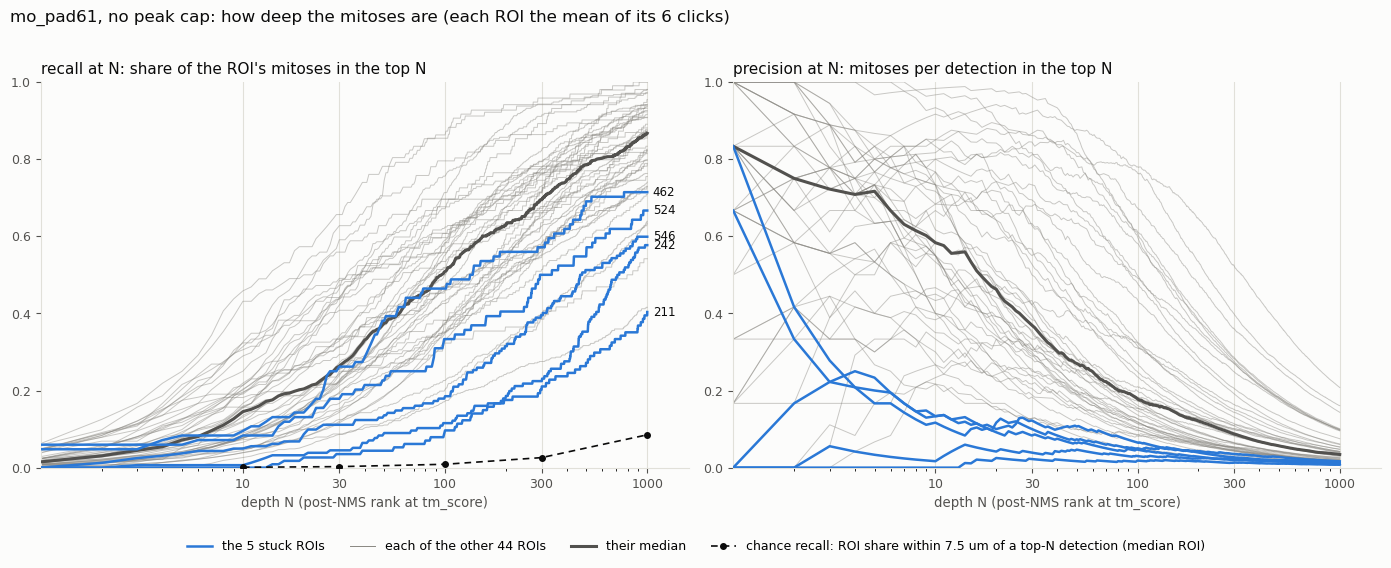

-> deep_pool_recall_precision.png; notebook total 45.2 min


In [8]:
# recall and precision against depth, every rank 1..1000, from the saved top 1000; each ROI's curve is the mean of its 6 clicks
SURFACE, INK, SECONDARY, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
STUCK_C = '#2a78d6'
ns = np.arange(1, SAVE_TOP + 1)
curves = {}
for (f, s), g in TOP.groupby(['file_name', 'seed_index']):
    hit = np.zeros(SAVE_TOP)
    h = (g.sort_values('rank')['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    hit[:len(h)] = h
    cum = np.cumsum(hit)
    n_gt = PR.loc[(PR['file_name'] == f) & (PR['seed_index'] == s), 'n_gt_mitotic'].iat[0]
    curves.setdefault(f, []).append((cum / n_gt, cum / np.minimum(ns, len(h))))
roi_curves = {f: (np.mean([c[0] for c in v], axis=0), np.mean([c[1] for c in v], axis=0)) for f, v in curves.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), facecolor=SURFACE)
for j, (ax, title) in enumerate(zip(axes, ('recall at N: share of the ROI\'s mitoses in the top N', 'precision at N: mitoses per detection in the top N'))):
    ax.set_facecolor(SURFACE)
    others = [roi_curves[f][j] for f in roi_curves if f not in STUCK]
    for c in others:
        ax.plot(ns, c, color=MUTED, linewidth=0.7, alpha=0.45, zorder=1)
    if others:
        ax.plot(ns, np.median(others, axis=0), color=SECONDARY, linewidth=2.2, zorder=3)
    for f in STUCK:
        if f in roi_curves:
            y = roi_curves[f][j]
            ax.plot(ns, y, color=STUCK_C, linewidth=1.8, zorder=4)
            if j == 0:   # labelled on the recall panel only; on the precision panel the five lines sit on top of each other near 0
                ax.annotate(f.replace('.tiff', ''), (ns[-1], y[-1]), xytext=(4, 0), textcoords='offset points', fontsize=8.5, color=INK, va='center')
    if j == 0:
        cov = ROI[[f'coverage_{n}' for n in DEPTHS]].median().to_numpy()
        ax.plot(DEPTHS, cov, color=INK, linewidth=1.2, linestyle=(0, (4, 3)), marker='o', markersize=4, zorder=5)
    ax.set_xscale('log')
    ax.set_xlim(1, SAVE_TOP * 1.6)
    ax.set_ylim(0, 1)
    for n in DEPTHS:
        ax.axvline(n, color=GRID, linewidth=0.8, zorder=0)
    ax.set_xticks(DEPTHS)
    ax.set_xticklabels([str(n) for n in DEPTHS])
    ax.set_xlabel('depth N (post-NMS rank at tm_score)', fontsize=9.5, color=SECONDARY)
    ax.set_title(title, fontsize=11, color=INK, loc='left')
    ax.tick_params(colors=SECONDARY, labelsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'):
        ax.spines[sp].set_color(GRID)
handles = [mlines.Line2D([], [], color=STUCK_C, linewidth=1.8, label='the 5 stuck ROIs'), mlines.Line2D([], [], color=MUTED, linewidth=0.7, label='each of the other 44 ROIs'), mlines.Line2D([], [], color=SECONDARY, linewidth=2.2, label='their median'), mlines.Line2D([], [], color=INK, linewidth=1.2, linestyle=(0, (4, 3)), marker='o', markersize=4, label='chance recall: ROI share within 7.5 um of a top-N detection (median ROI)')]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle(f'{ARM}, no peak cap: how deep the mitoses are (each ROI the mean of its 6 clicks)', fontsize=12, color=INK, x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(FIG_PATH, dpi=130, facecolor=SURFACE)
plt.show()
print(f'-> {FIG_PATH}; notebook total {(time.time() - NB_T0) / 60:.1f} min')

## Reading the result

**Every gate held on all 294 searches.** Each template's SHA-1, the 100-peak prefix, and the recorded top 30 and
`tp_at_10/20/30` all reproduced, at both `tm_score` and `chromatin_od`. The run took 45 min.

**The uncapped pool is the whole ROI.** A search keeps a median 15,564 detections (12,008-18,367) from about 26,000
peaks. Together they cover about 93% of the ROI within 7.5 um, so "found somewhere in the pool" (99.8% of mitoses) means
nothing on its own. The depth numbers below are the informative ones.

**The five stuck ROIs: their mitoses are in the list, but deep and diluted.**

| depth N | mitoses in top N, stuck 5 | other 44 | mitoses per detection, stuck 5 | other 44 | ceiling P@10, stuck 5 | other 44 |
|---|---|---|---|---|---|---|
| 30 | 2.2 | 13.7 | 7.3% | 45.5% | 0.22 | 0.87 |
| 100 | 4.2 | 27.1 | 4.2% | 27.1% | 0.42 | 0.96 |
| 300 | 7.1 | 39.3 | 2.4% | 13.1% | 0.69 | 0.99 |
| 1000 | 11.6 | 49.1 | 1.2% | 4.9% | 0.92 | 1.00 |

- The five have 14-27 mitoses each once the click is excluded. The median one first appears at rank 623, against 126 on
  the other 44.
- The template still prefers them over chance: recall is 15x chance at N = 300 and 7x at N = 1000. The preference is just
  weak.
- They split in two. `462` and `524` have about half their mitoses by rank 300. `211` and `242` have about a fifth, and
  `546` two-fifths.
- Every one of the five has a tail of 3-6 mitoses first matched past rank 2,400, in a 15,000-long list. The template has
  essentially no preference for those.

**What that means for a shape re-rank of the deeper pool.** To reach P@10 = 0.5 on a stuck ROI from its top 300, a
score must put 5 of its ~7 mitoses into the top 10, above all but 5 of ~293 other detections. That is ~70% sensitivity at
a ~2% false-positive rate. The requirement is arithmetic. How close a shape feature gets at this depth has not been
measured.

As a rough guide only, an equal-variance model gives how many mitoses a feature would put into that top 10:
- at solidity's pooled 0.68 (the chance a mitosis outranks a false positive inside the top 30): 0.5-1.2 per ROI. That is
  about what `tm_score` gets now (0-1.3).
- at the 0.85 measured in melanoma: 1.3-3.2 per ROI. `524` and `546`, both melanoma, are the best case at 2.2 and 3.2.

Both figures assume a top-30 value carries over to depth 300. Either way, shape alone would not bring these ROIs near
0.5. The template does prefer their mitoses over area chance (15x at N = 300), but too weakly to surface them.

**For all 49 ROIs, the re-rank ceiling does rise with depth.** A perfect re-ranker would reach P@10 of 0.80 from the top
30, 0.90 from the top 100 and 0.96 from the top 300. For P@20 the figures are 0.57, 0.73 and 0.82. The top-30 value
matches the 0.805 measured earlier on `fill_61`. These ceilings assume a perfect sort, so they are upper bounds, not
estimates.

**Scope.** Descriptive only. The five ROIs were chosen for their poor top 10, and the other 44 are a contrast, not a
control.
